<a href="https://colab.research.google.com/github/FantinelBruna/pcd-unijui/blob/main/trabalho/projetoIndividual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise das formas de pagamento em compras online
**Bruna Fantinel**

## 1. Definição do problema

O tema deste trabalho é a análise das formas de pagamento utilizadas em compras online. O objetivo é investigar quais meios de pagamento são mais utilizados, quais apresentam os maiores valores médios e como ocorre o parcelamento das compras.

Para realizar a análise, será utilizada uma base pública da Olist, que contém registros de pagamentos relacionados a pedidos do comércio eletrônico brasileiro entre 2016 e 2018.

A partir desses dados, serão identificadas as formas de pagamento mais frequentes, os valores médios das transações, a quantidade de parcelas utilizadas e as diferenças entre os tipos de pagamento.

**Fonte dos dados:** [Olist — GitHub](https://github.com/olist/work-at-olist-data/blob/master/datasets/olist_order_payments_dataset.csv).

Os resultados representam apenas os registros disponíveis nessa base de dados.

## 2. Importação e exploração dos dados

Os dados foram obtidos de um arquivo CSV público da Olist, disponível no GitHub, e importados utilizando a biblioteca Pandas.

Inicialmente, são exibidas as primeiras linhas da tabela para conhecer sua estrutura. Em seguida, são verificadas a quantidade de registros, as colunas disponíveis, os tipos de dados e a existência de valores ausentes.

O conjunto possui 103.886 registros e 5 colunas, contendo informações sobre a identificação dos pedidos, o tipo de pagamento, a sequência do pagamento, a quantidade de parcelas e o valor pago.

Na verificação inicial, não foram encontrados valores ausentes nas colunas analisadas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/olist_order_payments_dataset.csv"
df = pd.read_csv(url)

df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [12]:
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])
print("\n")
print("Colunas:", list(df.columns))
print("\n")
print("Tipos de dados:")
print(df.dtypes)
print("\n")
print("Valores ausentes:")
print(df.isnull().sum())
print("\n")
print("Tipos de pagamento encontrados:")
print(df["payment_type"].unique())
print("\n")
print("Pagamentos com valor zero:")
print(len(df[df["payment_value"] == 0]))
print("\n")
print("Pagamentos com zero parcelas:")
print(len(df[df["payment_installments"] == 0]))

Quantidade de linhas: 103886
Quantidade de colunas: 5


Colunas: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


Tipos de dados:
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object


Valores ausentes:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64


Tipos de pagamento encontrados:
['credit_card' 'boleto' 'voucher' 'debit_card' 'not_defined']


Pagamentos com valor zero:
9


Pagamentos com zero parcelas:
2


## 3. Preparação dos dados

Nesta etapa, é criada uma cópia dos dados originais para realizar os tratamentos sem modificar a tabela inicial.

São verificados os registros com informações ausentes nos campos de tipo de pagamento, valor e quantidade de parcelas. Também são considerados apenas os pagamentos com valores iguais ou superiores a zero, evitando a utilização de valores negativos na análise.

Após esses tratamentos, a quantidade de registros permaneceu em 103.886, pois nenhum registro precisou ser removido pelos critérios utilizados.

Como os valores já estão armazenados nos tipos adequados para os cálculos, não foi necessário realizar conversões de dados.

In [4]:
pagamentos = df.copy()

#removendo linhas sem as informações necessárias
pagamentos = pagamentos.dropna(subset=["payment_type", "payment_value", "payment_installments"])

#apenas pagamentos com valor igual ou maior que zero
pagamentos = pagamentos[pagamentos["payment_value"] >= 0]

print("Registros antes da limpeza:", len(df))
print("Registros depois da limpeza:", len(pagamentos))

pagamentos.head()

Registros antes da limpeza: 103886
Registros depois da limpeza: 103886


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


## 4. Análise dos dados

A análise busca identificar quais formas de pagamento são mais utilizadas e comparar os valores registrados em cada uma delas.

Primeiramente, são calculadas a quantidade e a porcentagem de registros por tipo de pagamento. Depois, são identificados o valor médio, o menor e o maior valor, além das médias específicas de cada forma de pagamento.

Também é realizada uma análise do parcelamento, verificando as quantidades de parcelas mais frequentes e o percentual de pagamentos realizados em mais de uma parcela.

Por fim, são apresentados dois gráficos de barras para facilitar a comparação entre as formas de pagamento, considerando a quantidade de registros e os valores médios.

Essas operações permitem compreender melhor as características dos pagamentos presentes na base analisada.

In [5]:
#quantidade de pagamentos por forma de pagamento
quantidade = pagamentos["payment_type"].value_counts()
print("Quantidade por forma de pagamento:")
print(quantidade)
print("\n")

#percentual de cada forma de pagamento
percentual = pagamentos["payment_type"].value_counts(normalize=True) * 100
print("Percentual por forma de pagamento:")
print(percentual.round(2))

Quantidade por forma de pagamento:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


Percentual por forma de pagamento:
payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64


In [6]:
#valores dos pagamentos
print("Valor médio dos pagamentos: R$", round(pagamentos["payment_value"].mean(), 2))
print("Menor valor: R$", round(pagamentos["payment_value"].min(), 2))
print("Maior valor: R$", round(pagamentos["payment_value"].max(), 2))
print("\n")

#média do valor por tipo de pagamento
media_por_tipo = pagamentos.groupby("payment_type")["payment_value"].mean()
print("Valor médio por forma de pagamento:")
print(media_por_tipo.round(2))

Valor médio dos pagamentos: R$ 154.1
Menor valor: R$ 0.0
Maior valor: R$ 13664.08


Valor médio por forma de pagamento:
payment_type
boleto         145.03
credit_card    163.32
debit_card     142.57
not_defined      0.00
voucher         65.70
Name: payment_value, dtype: float64


In [7]:
#análise do parcelamento
print("Quantidade de parcelas mais frequente:")
print(pagamentos["payment_installments"].value_counts().head(10))
print("\n")

#verificar pagamentos com mais de uma parcela
parcelados = pagamentos[pagamentos["payment_installments"] > 1]
print("Pagamentos com mais de uma parcela:", len(parcelados))
print("Percentual dos pagamentos com mais de uma parcela:", round(len(parcelados) / len(pagamentos) * 100, 2), "%")

Quantidade de parcelas mais frequente:
payment_installments
1     52543
2     12413
3     10461
4      7098
10     5331
5      5239
8      4268
6      3920
7      1626
9       644
Name: count, dtype: int64


Pagamentos com mais de uma parcela: 51341
Percentual dos pagamentos com mais de uma parcela: 49.42 %


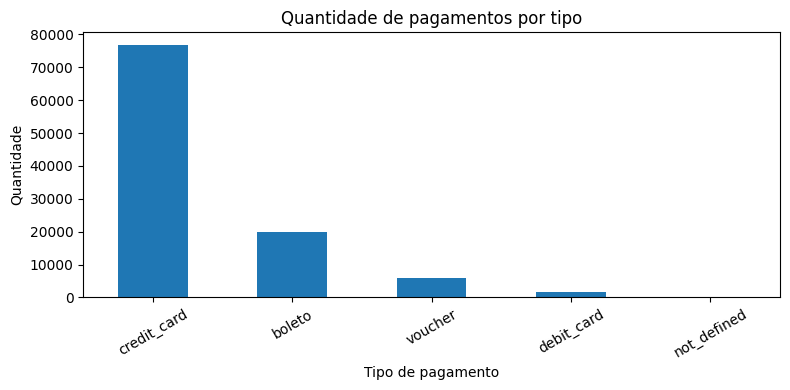

In [8]:
#gráfico da quantidade por tipo de pagamento
quantidade.plot(kind="bar", figsize=(8, 4))
plt.title("Quantidade de pagamentos por tipo")
plt.xlabel("Tipo de pagamento")
plt.ylabel("Quantidade")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

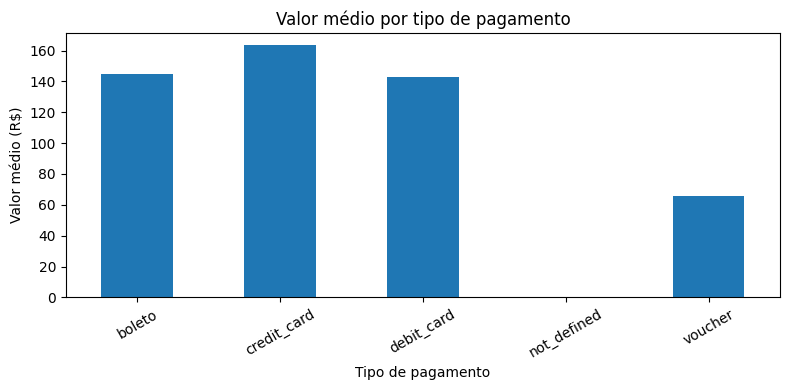

In [ ]:
#gráfico do valor médio por tipo de pagamento
media_por_tipo.plot(kind="bar", figsize=(8, 4))
plt.title("Valor médio por tipo de pagamento")
plt.xlabel("Tipo de pagamento")
plt.ylabel("Valor médio (R$)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Documentação e conclusão

O trabalho foi desenvolvido utilizando Python e as bibliotecas Pandas e Matplotlib. O Pandas foi utilizado para importar, organizar, filtrar e analisar os dados, enquanto o Matplotlib permitiu a criação dos gráficos.

Os códigos foram organizados de acordo com as etapas do trabalho, desde a importação e preparação dos dados até os cálculos e a visualização dos resultados.

A análise mostrou que o cartão de crédito foi a forma de pagamento mais utilizada, com 76.795 registros, representando aproximadamente 73,92% do total. Em segundo lugar aparece o boleto, com 19,04%.

O valor médio geral dos pagamentos foi de R$ 154,10. Entre as formas de pagamento identificadas, o cartão de crédito apresentou a maior média, de R$ 163,32, enquanto o voucher apresentou a menor, de R$ 65,70.

Em relação ao parcelamento, aproximadamente 49,42% dos registros apresentaram mais de uma parcela, mostrando que o pagamento parcelado possui uma participação significativa na base analisada.

Com isso, foi possível identificar diferenças na frequência de utilização, nos valores e nas condições de parcelamento das formas de pagamento.

Os resultados são referentes aos registros da Olist disponíveis no conjunto de dados, não representando todas as compras realizadas no comércio eletrônico brasileiro.

In [11]:
mais_utilizado = quantidade.idxmax()
maior_media = media_por_tipo.idxmax()

print("Forma de pagamento mais utilizada:", mais_utilizado)
print("Quantidade de registros dessa forma:", quantidade.max())
print("Forma de pagamento com maior valor médio:", maior_media)
print("Maior média: R$", round(media_por_tipo.max(), 2))
print("Total de pagamentos analisados:", len(pagamentos))

Forma de pagamento mais utilizada: credit_card
Quantidade de registros dessa forma: 76795
Forma de pagamento com maior valor médio: credit_card
Maior média: R$ 163.32
Total de pagamentos analisados: 103886
